## Turning a map of 50 US states in to a map of US regions (according to survey data)

In [6]:
## installing packages
# !pip install geopandas
# !pip install shapely

In [7]:
import geopandas as gpd
import numpy as np
from shapely.affinity import rotate, scale, translate

In [8]:
unprojected = gpd.read_file('unclean/map_data/cb_2018_us_state_5m.shp')

<hr>

### First I am re-projecting the whole map and moving Alaska and Hawaii to be below the contiguous US

In [9]:
# Separate Contiguous US, Alaska (FIPS '02'), and Hawaii (FIPS '15')
conus = unprojected[~unprojected["STATEFP"].isin(["02", "15", "60", "66", "69", "72", "78"])].to_crs("EPSG:5070")
alaska = unprojected[unprojected["STATEFP"] == "02"].to_crs("EPSG:3338")  # Alaska Albers
hawaii = unprojected[unprojected["STATEFP"] == "15"].to_crs("ESRI:102007")  # Hawaii Albers

In [10]:
# 3. Scale Alaska around its OWN center so its position stays predictable
alaska_center = alaska.geometry.unary_union.centroid

alaska["geometry"] = alaska.geometry.apply(
    lambda geom: translate(
        scale(geom, xfact=0.45, yfact=0.45, origin=alaska_center),
        xoff=-alaska_center.x - 1200000,  # Exact X position in EPSG:5070
        yoff=-alaska_center.y + 500000,   # Exact Y position in EPSG:5070
    )
)
alaska = alaska.set_crs("EPSG:5070", allow_override=True)

# 4. Center Hawaii at (0, 0) first, then move it cleanly below Arizona/New Mexico
hawaii_center = hawaii.geometry.unary_union.centroid
hawaii["geometry"] = hawaii.geometry.apply(
    lambda geom: translate(
        geom,
        xoff=-hawaii_center.x - 2000000,  # Move west under AZ/NM
        yoff=-hawaii_center.y + 900000,   # Move south below the border
    )
)
hawaii = hawaii.set_crs("EPSG:5070", allow_override=True)

/var/folders/cj/ydzt191j61g6zb6y44vq3bnc0000gp/T/ipykernel_31202/1836118533.py:2: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  alaska_center = alaska.geometry.unary_union.centroid
/var/folders/cj/ydzt191j61g6zb6y44vq3bnc0000gp/T/ipykernel_31202/1836118533.py:14: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  hawaii_center = hawaii.geometry.unary_union.centroid


In [11]:
# 5. Recombine into a single GeoDataFrame ready for plotting or export
us_states = gpd.pd.concat([conus, alaska, hawaii], ignore_index=True)

In [12]:
us_states.head()

,STATEFP,STATENS,AFFGEOID,GEOID,STUSPS,NAME,LSAD,ALAND,AWATER,geometry
0,31,01779792,0400000US31,31,NE,Nebraska,00,198956658395,1371829134,"POLYGON ((-669722.642 2044992.994, -668534.295..."
1,53,01779804,0400000US53,53,WA,Washington,00,172112588220,12559278850,"MULTIPOLYGON (((-1955187.931 3053096.634, -195..."
2,35,00897535,0400000US35,35,NM,New Mexico,00,314196306401,728776523,"POLYGON ((-1231344.076 1018550.43, -1231015.83..."
3,46,01785534,0400000US46,46,SD,South Dakota,00,196346981786,3382720225,"POLYGON ((-633753.012 2472318.335, -633164.159..."
4,48,01779801,0400000US48,48,TX,Texas,00,676653171537,19006305260,"POLYGON ((-1000296.509 1036577.114, -999788.64..."


<hr>

### Now grouping my states into regions and dissolving

In [13]:
## 15 states (14 w/o DC)
Southeast = ['Florida', 'Louisiana', 'Alabama', 'Kentucky', 'North Carolina', 'Delaware', 'Arkansas', 'Virginia', 'Georgia', 'Maryland', 'Mississippi', 'Tennessee', 'South Carolina', 'West Virginia', 'District of Columbia']

## 12 states
Midwest = ['Missouri', 'Ohio', 'Wisconsin', 'Nebraska', 'Michigan', 'Indiana', 'South Dakota', 'North Dakota', 'Illinois', 'Iowa', 'Kansas', 'Minnesota']

## 10 states
West = ['California', 'Washington', 'Idaho', 'Oregon', 'Nevada', 'Utah', 'Colorado', 'Wyoming', 'Montana', 'Hawaii']

## 9 states
Northeast = ['New York', 'Connecticut', 'Pennsylvania', 'Massachusetts', 'New Jersey', 'Maine', 'Rhode Island', 'New Hampshire', 'Vermont']

## 3 states
Southwest = ['Oklahoma', 'Texas', 'Arizona']

In [14]:
conditions = [us_states['NAME'].isin(Southeast),
              us_states['NAME'].isin(Northeast),
              us_states['NAME'].isin(West),
              us_states['NAME'].isin(Midwest),
              us_states['NAME'].isin(Southwest)]

choices = ['Southeast', 'Northeast', 'West', 'Midwest', 'Southwest']

us_states['region'] = np.select(conditions, choices, default="None")

In [15]:
us_states.head()

,STATEFP,STATENS,AFFGEOID,GEOID,STUSPS,NAME,LSAD,ALAND,AWATER,geometry,region
0,31,01779792,0400000US31,31,NE,Nebraska,00,198956658395,1371829134,"POLYGON ((-669722.642 2044992.994, -668534.295...",Midwest
1,53,01779804,0400000US53,53,WA,Washington,00,172112588220,12559278850,"MULTIPOLYGON (((-1955187.931 3053096.634, -195...",West
2,35,00897535,0400000US35,35,NM,New Mexico,00,314196306401,728776523,"POLYGON ((-1231344.076 1018550.43, -1231015.83...",None
3,46,01785534,0400000US46,46,SD,South Dakota,00,196346981786,3382720225,"POLYGON ((-633753.012 2472318.335, -633164.159...",Midwest
4,48,01779801,0400000US48,48,TX,Texas,00,676653171537,19006305260,"POLYGON ((-1000296.509 1036577.114, -999788.64...",Southwest


In [16]:
us_states[us_states['region']=="None"]

,STATEFP,STATENS,AFFGEOID,GEOID,STUSPS,NAME,LSAD,ALAND,AWATER,geometry,region
2,35,00897535,0400000US35,35,NM,New Mexico,00,314196306401,728776523,"POLYGON ((-1231344.076 1018550.43, -1231015.83...",None
49,02,01785533,0400000US02,02,AK,Alaska,00,1478839695958,245481577452,"MULTIPOLYGON (((-2037760.212 63497.95, -203762...",None


In [17]:
us_regions = us_states.dissolve(by='region', as_index=False)

In [18]:
us_regions.head()

,region,geometry,STATEFP,STATENS,AFFGEOID,GEOID,STUSPS,NAME,LSAD,ALAND,AWATER
0,Midwest,"MULTIPOLYGON (((605702.932 1570825.82, 606311....",31,01779792,0400000US31,31,NE,Nebraska,00,198956658395,1371829134
1,None,"MULTIPOLYGON (((-1758108.51 -6493.05, -1758349...",35,00897535,0400000US35,35,NM,New Mexico,00,314196306401,728776523
2,Northeast,"MULTIPOLYGON (((1726338.922 2033848.17, 172656...",42,01779798,0400000US42,42,PA,Pennsylvania,00,115884442321,3394589990
3,Southeast,"MULTIPOLYGON (((518084.329 678614.12, 511785.5...",21,01779786,0400000US21,21,KY,Kentucky,00,102279490672,2375337755
4,Southwest,"MULTIPOLYGON (((-999788.644 1037184.531, -9990...",48,01779801,0400000US48,48,TX,Texas,00,676653171537,19006305260


<hr>

### Viewing the final map to confirm it looks right before exporting

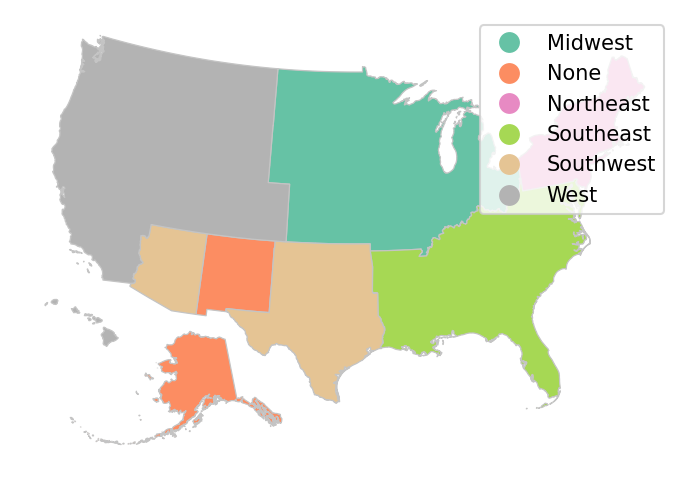

In [19]:
import matplotlib.pyplot as plt

# Match the aspect ratio and small size of your dashboard widget (e.g., 5x3 inches)
fig, ax = plt.subplots(figsize=(5, 3), dpi=150)

us_regions.plot(
    column='region',
    categorical=True,
    cmap='Set2',
    legend=True,
    ax=ax,
    edgecolor="#c4c4c4",  # Crisp white state/region borders
    linewidth=0.6
)

# Turn off the meter coordinate axes so it looks like a clean dashboard visual
ax.set_axis_off()
plt.tight_layout(pad=0)
plt.show()

In [20]:
us_regions.head()

,region,geometry,STATEFP,STATENS,AFFGEOID,GEOID,STUSPS,NAME,LSAD,ALAND,AWATER
0,Midwest,"MULTIPOLYGON (((605702.932 1570825.82, 606311....",31,01779792,0400000US31,31,NE,Nebraska,00,198956658395,1371829134
1,None,"MULTIPOLYGON (((-1758108.51 -6493.05, -1758349...",35,00897535,0400000US35,35,NM,New Mexico,00,314196306401,728776523
2,Northeast,"MULTIPOLYGON (((1726338.922 2033848.17, 172656...",42,01779798,0400000US42,42,PA,Pennsylvania,00,115884442321,3394589990
3,Southeast,"MULTIPOLYGON (((518084.329 678614.12, 511785.5...",21,01779786,0400000US21,21,KY,Kentucky,00,102279490672,2375337755
4,Southwest,"MULTIPOLYGON (((-999788.644 1037184.531, -9990...",48,01779801,0400000US48,48,TX,Texas,00,676653171537,19006305260


In [21]:
us_regions_export = us_regions[['region', 'geometry']]
us_regions_export.to_file('regions_map.geojson', driver="GeoJSON")